# Demographics Break Down

In [1]:
import os
os.chdir("../")

from argparse import Namespace

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from data import *
from run import *

data_path = "../excel_data"

## Get Valid Samples

Rebuild the datasets as done in the code to get an accurate representation of used samples

In [2]:
model="gemma"

args = Namespace(
    seed=0, 
    data_path=f"../{model}_multimodal_bins",
    test_path=f"../{model}_multimodal_bins_rw",
    clinical=True,
    path_lang=True,
    rad_lang=True,
    label_col="survival_days",
    sparse=False,
    survival_years=2
)

rih, rw = get_datasets(args, keys=["slide_ids", "survival_days", "survival_right_censor", "stage"]) #
rih_loader, rw_loader = DataLoader(rih), DataLoader(rw)
#dict_keys(['label', 'label_mask', 'path_lang_mask', 'path_lang', 'rad_lang_mask', 'rad_lang', 'clinical_mask', 'clinical', 'slide_ids', 'survival_days', 'survival_right_censor'])
rih_df, rw_df = pd.read_excel(f"{data_path}/PDAC_IHC.xlsx"), pd.read_excel(f"{data_path}/Combined_Clinical_Lab.xlsx")

5-Fold Avg + 95% CI
AUC: 0.800 ([nan], [nan])
C Ind: 0.593 (0.5870192244827015, 0.5994976294498826)
----------
Bootstrapped Avg + 95% CI
AUC: 0.800 (0.800, 0.800)
C-Index: 0.604 (0.602, 0.606)
From 4995 bootstrap samples


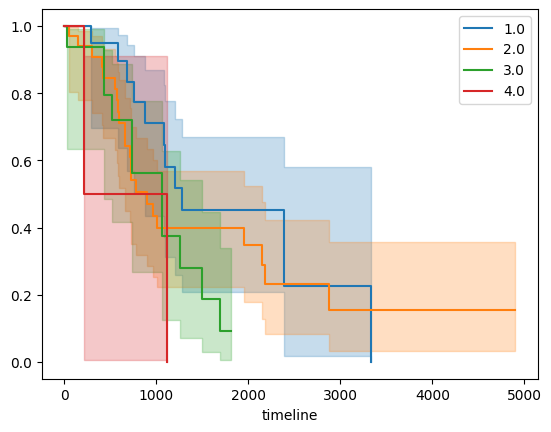

In [ ]:
from util import Bootstrap

yrs = 2.0
seed = 1

from torchsurv.metrics.cindex import ConcordanceIndex
from torchsurv.metrics.auc import Auc

strat = lambda data: data[1] > args.survival_years * DAYS_IN_YR

def cind(death, times, preds):
    death = death.bool()

    cindex = ConcordanceIndex()
    c = cindex(preds, death, times)
    return c

def auc(death, times, preds):
    death = death.bool()

    auc = Auc()
    a = auc(preds, death, times, new_time = torch.ones((1,)) * args.survival_years * DAYS_IN_YR)
    return a
re = 100
ci_res, auc_res = Bootstrap("C-Index", cind, stratify=strat, n_resample=re), Bootstrap("AUC", auc, stratify=strat, n_resample=re, random_state=seed)

from torch.utils.data import ConcatDataset
from sklearn.model_selection import train_test_split, KFold
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt
from sksurv.metrics import concordance_index_censored, cumulative_dynamic_auc
from torchsurv.metrics.cindex import ConcordanceIndex
import scipy.stats as stats

torch.manual_seed(seed)
np.random.seed(seed)

all_ds = ConcatDataset([rih, rw])
all_loader = DataLoader(all_ds)
stages, time, event = [], [], []
for s in all_loader:
    stages.append(s['stage'].item())
    time.append(s['survival_days'].item())
    event.append(not s['survival_right_censor'].item())

df = pd.DataFrame({"Stage": stages, "Survival Time": time, "Survival Event": event})

tv, test_inds = train_test_split(
    np.arange(len(df)),
    test_size=0.15,
    random_state=args.seed,
)

test = df.iloc[test_inds]

kf = KFold(n_splits=5, shuffle=True, random_state=seed)
splits = kf.split(X=tv)

ax = plt.subplot(111)
cinds = []
aucs = []

for split, (train_inds, val_inds) in enumerate(splits):
    train, val = df.iloc[train_inds], df.iloc[val_inds]
    # Initialize the fitter
    kmf = KaplanMeierFitter()

    ax = plt.subplot(111)

    s_prop = {}

    # Fit and plot each group separately onto the same axis (ax)
    for name, grouped_df in train.groupby("Stage"):
        kmf.fit(
            grouped_df["Survival Time"],
            event_observed=grouped_df["Survival Event"],
            label=name,
        )
        s_prop[name] = dict(kmf.survival_function_at_times([yrs*DAYS_IN_YR]))

        if split == 4: kmf.plot_survival_function(ax=ax)

    km_risk = 1 - pd.DataFrame.from_dict(s_prop, orient='index')

    df_km_2yr = test['Stage'].map(dict(km_risk[yrs * DAYS_IN_YR]))

    cindex = ConcordanceIndex()
    cind = cindex(
        torch.from_numpy(df_km_2yr.to_numpy()), 
        torch.from_numpy(test['Survival Event'].to_numpy(dtype=bool)), 
        torch.from_numpy(test['Survival Time'].to_numpy())
    )

    auc = Auc()
    a = auc(
        torch.from_numpy(df_km_2yr.to_numpy()), 
        torch.from_numpy(test['Survival Event'].to_numpy(dtype=bool)), 
        torch.from_numpy(test['Survival Time'].to_numpy()),
        new_time = torch.ones((1,)) * args.survival_years * DAYS_IN_YR
    )

    cinds.append(cind)
    aucs.append(a)

    test_samples = [torch.from_numpy(test['Survival Event'].to_numpy(dtype=bool)), 
                    torch.from_numpy(test['Survival Time'].to_numpy()),
                    torch.from_numpy(df_km_2yr.to_numpy())]
    ci_res.add(*test_samples)
    auc_res.add(*test_samples)

auc_avg = np.mean(aucs)
auc_err = stats.sem(aucs)

ci_avg = np.mean(cinds)
ci_err = stats.sem(cinds)

auc_ci = stats.t.interval(confidence=.95, df=4, loc=auc_avg, scale=auc_err)
# auc_ci = [float(n) for n in auc_ci]
c_ci = stats.t.interval(confidence=.95, df=4, loc=ci_avg, scale=ci_err)
# c_ci = [float(n) for n in c_ci]

print(f"5-Fold Avg + 95% CI")
print(f"AUC: {auc_avg:.3f} ({auc_ci[0]}, {auc_ci[1]})")
print(f"C Ind: {ci_avg:.3f} ({c_ci[0]}, {c_ci[1]})")

print(f"{"--" * 5}")
print(f"Bootstrapped Avg + 95% CI")
print(str(auc_res))
print(str(ci_res))
print(f"From {len(ci_res.entries)} bootstrap samples")

plt.show()

5-Fold Avg + 95% CI
AUC: 0.587 ([0.57638876], [0.59821446])
C Ind: 0.507 (0.490882315910912, 0.5233170798594807)
----------
Bootstrapped Avg + 95% CI
AUC: 0.635 (0.633, 0.636)
C-Index: 0.506 (0.502, 0.510)
From 500 bootstrap samples


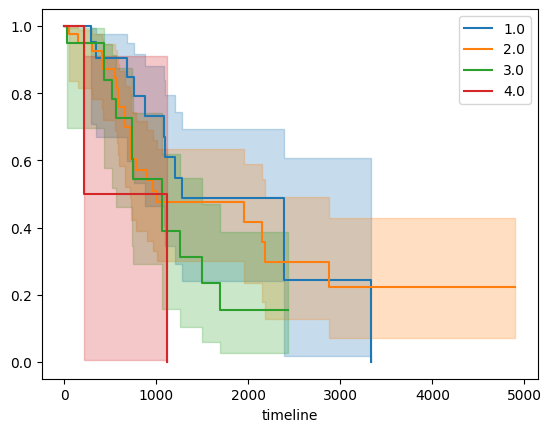

In [12]:
from util import Bootstrap

yrs = 2.0
seed = 1

from torchsurv.metrics.cindex import ConcordanceIndex
from torchsurv.metrics.auc import Auc

strat = lambda data: data[1] > args.survival_years * DAYS_IN_YR

def cind(death, times, preds):
    death = death.bool()

    cindex = ConcordanceIndex()
    c = cindex(preds, death, times)
    return c

def auc(death, times, preds):
    death = death.bool()

    auc = Auc()
    a = auc(preds, death, times, new_time = torch.ones((1,)) * args.survival_years * DAYS_IN_YR)
    return a
re = 100
ci_res, auc_res = Bootstrap("C-Index", cind, stratify=strat, n_resample=re), Bootstrap("AUC", auc, stratify=strat, n_resample=re, random_state=seed)


from sklearn.model_selection import train_test_split, KFold
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt
from sksurv.metrics import concordance_index_censored, cumulative_dynamic_auc
from torchsurv.metrics.cindex import ConcordanceIndex
import scipy.stats as stats

torch.manual_seed(seed)
np.random.seed(seed)

rih_loader = DataLoader(rih)
rih_stages, rih_time, rih_event = [], [], []
for s in all_loader:
    rih_stages.append(s['stage'].item())
    rih_time.append(s['survival_days'].item())
    rih_event.append(not s['survival_right_censor'].item())
rih_df = pd.DataFrame({"Stage": rih_stages, "Survival Time": rih_time, "Survival Event": rih_event})

rw_loader = DataLoader(rw)
rw_stages, rw_time, rw_event = [], [], []
for s in all_loader:
    rw_stages.append(s['stage'].item())
    rw_time.append(s['survival_days'].item())
    rw_event.append(not s['survival_right_censor'].item())
test = pd.DataFrame({"Stage": rw_stages, "Survival Time": rw_time, "Survival Event": rw_event})

kf = KFold(n_splits=5, shuffle=True, random_state=seed)
splits = kf.split(X=np.arange(len(rih_df)))

ax = plt.subplot(111)
cinds = []
aucs = []

for split, (train_inds, val_inds) in enumerate(splits):
    train, val = rih_df.iloc[train_inds], rih_df.iloc[val_inds]
    # Initialize the fitter
    kmf = KaplanMeierFitter()

    ax = plt.subplot(111)

    s_prop = {}

    # Fit and plot each group separately onto the same axis (ax)
    for name, grouped_df in train.groupby("Stage"):
        kmf.fit(
            grouped_df["Survival Time"],
            event_observed=grouped_df["Survival Event"],
            label=name,
        )
        s_prop[name] = dict(kmf.survival_function_at_times([yrs*DAYS_IN_YR]))

        if split == 4: kmf.plot_survival_function(ax=ax)

    km_risk = 1 - pd.DataFrame.from_dict(s_prop, orient='index')

    df_km_2yr = test['Stage'].map(dict(km_risk[yrs * DAYS_IN_YR]))

    cindex = ConcordanceIndex()
    cind = cindex(
        torch.from_numpy(df_km_2yr.to_numpy()), 
        torch.from_numpy(test['Survival Event'].to_numpy(dtype=bool)), 
        torch.from_numpy(test['Survival Time'].to_numpy())
    )

    auc = Auc()
    a = auc(
        torch.from_numpy(df_km_2yr.to_numpy()), 
        torch.from_numpy(test['Survival Event'].to_numpy(dtype=bool)), 
        torch.from_numpy(test['Survival Time'].to_numpy()),
        new_time = torch.ones((1,)) * args.survival_years * DAYS_IN_YR
    )

    cinds.append(cind)
    aucs.append(a)

    test_samples = [torch.from_numpy(test['Survival Event'].to_numpy(dtype=bool)), 
                    torch.from_numpy(test['Survival Time'].to_numpy()),
                    torch.from_numpy(df_km_2yr.to_numpy())]
    ci_res.add(*test_samples)
    auc_res.add(*test_samples)

auc_avg = np.mean(aucs)
auc_err = stats.sem(aucs)

ci_avg = np.mean(cinds)
ci_err = stats.sem(cinds)

auc_ci = stats.t.interval(confidence=.95, df=4, loc=auc_avg, scale=auc_err)
c_ci = stats.t.interval(confidence=.95, df=4, loc=ci_avg, scale=ci_err)

print(f"5-Fold Avg + 95% CI")
print(f"AUC: {auc_avg:.3f} ({auc_ci[0]}, {auc_ci[1]})")
print(f"C Ind: {ci_avg:.3f} ({c_ci[0]}, {c_ci[1]})")

print(f"{"--" * 5}")
print(f"Bootstrapped Avg + 95% CI")
print(str(auc_res))
print(str(ci_res))
print(f"From {len(ci_res.entries)} bootstrap samples")

plt.show()

In [ ]:
sample = next(iter(rw_loader))
sample.keys()

dict_keys(['label', 'label_mask', 'path_lang_mask', 'path_lang', 'rad_lang_mask', 'rad_lang', 'clinical_mask', 'clinical', 'slide_ids', 'survival_days', 'survival_right_censor', 'stage'])

In [34]:
#for each sample in loader, need to pull the id and survival time
rih_ids, rih_surv   = [], []
rw_ids, rw_surv     = [], []

for sample in rih_loader:
    rih_ids.append(sample['slide_ids'].item())
    rih_surv.append(sample['survival_days'].item())

for sample in rw_loader:
    rw_ids.append(sample['slide_ids'].item())
    rw_surv.append(sample['survival_days'].item())

rih_df = rih_df[rih_df['UniID of PDAC'].isin(rih_ids)]
rw_df = rw_df[rw_df['Patient ID'].isin(rw_ids)]

In [37]:
def desc_cat_column(df, col, mapping=None, mapping_name = None):
    """
    
    df: pandas dataframe
    col: column in df to summarize
    mapping: map the unique values in col (dict)
    mapping_name: name of mapped column
    """
    desc = pd.concat([df[col].value_counts(), df[col].value_counts(normalize=True)], axis=1)
    if mapping is not None:
        desc[mapping_name] = desc.index.to_series().map(mapping)
        desc = desc[[mapping_name, 'count', 'proportion']]

    return desc

#waht are the covariates relevant here?
#i guess we can do like age, gender, survival time, tumor grade 

#survival time: just grab from dataloader

#RIH DATA: "PDAC IHC.xlsx"
#age: 'Age at Diagnosis'
#gender: 'Sex'
#tumor grade: 'AJCC Pathologic Stage Group'

#RW DATA: Combined_Clinical_lab.xlsx -> make sure to re-export this
#age: 'Age'
#gender: '''Sex \nFemale=0\nMale=1'''
#tumor grade: 'AJCC Pathologic Stage Group'

### Age

In [38]:
print(rih_df['Age at Diagnosis'].describe())
print(rw_df['Age'].describe())

count    70.000000
mean     67.471429
std      11.704974
min      30.000000
25%      60.250000
50%      68.500000
75%      77.000000
max      88.000000
Name: Age at Diagnosis, dtype: float64
count    32.000000
mean     70.062500
std      11.401577
min      29.000000
25%      64.000000
50%      71.500000
75%      75.500000
max      94.000000
Name: Age, dtype: float64


In [39]:
print(desc_cat_column(rih_df, 'Sex'))
print(desc_cat_column(rw_df, 'Sex \nFemale=0\nMale=1', {0: "Female", 1: "Male"}, 'Sex'))

        count  proportion
Sex                      
Male       40    0.571429
Female     30    0.428571
                           Sex  count  proportion
Sex \nFemale=0\nMale=1                           
1.0                       Male     19    0.527778
0.0                     Female     17    0.472222


In [47]:
rih_stage = desc_cat_column(rih_df, 'AJCC Pathologic Stage Group')
rih_stage.index = rih_stage.index.astype(str)
rih_stage = rih_stage.sort_index()
rw_stage = desc_cat_column(rw_df, 'AJCC Pathologic Stage Group')
rw_stage.index = rw_stage.index.astype(str)
rw_stage = rw_stage.sort_index()

print(rih_stage)
print(rw_stage)


                             count  proportion
AJCC Pathologic Stage Group                   
1                                1    0.014286
1A                               3    0.042857
1B                              12    0.171429
2A                               8    0.114286
2B                              30    0.428571
3                                9    0.128571
3A                               2    0.028571
3B                               3    0.042857
4                                2    0.028571
                             count  proportion
AJCC Pathologic Stage Group                   
1B                               4    0.121212
2A                               4    0.121212
2B                              19    0.575758
3                                3    0.090909
3A                               3    0.090909


In [50]:
print(list(rih_ids))
print(len(rih_ids))

[7, 10, 15, 19, 34, 38, 41, 60, 62, 69, 70, 72, 73, 76, 77, 80, 87, 88, 90, 92, 105, 108, 109, 119, 122, 125, 128, 130, 132, 134, 139, 143, 146, 150, 151, 153, 154, 155, 156, 157, 159, 164, 165, 166, 167, 168, 169, 171, 177, 178, 180, 183, 184, 185, 187, 195, 198, 202, 203, 204, 205, 209, 210, 212, 213, 214, 215, 227, 229, 230]
70


In [51]:
print(list(rw_ids))
print(len(rw_ids))

[4, 5, 9, 12, 19, 20, 26, 27, 31, 33, 36, 37, 39, 47, 60, 64, 73, 78, 82, 94, 103, 105, 106, 121, 127, 128, 132, 146, 149, 157, 162, 163, 172, 185, 191, 207]
36


In [ ]:
rih_surv = pd.DataFrame({"Survival (days)": rih_surv})
rw_surv = pd.DataFrame({"Survival (days)": rw_surv})

print(rih_surv["Survival (days)"].describe())
print(rih_surv["Survival (days)"].describe())